# **Lab 8 - Edge Detection (Task)**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'coffee.png'

img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print('Image shape:', img.shape)

Image shape: (400, 600, 3)


## **Task 1: Apply Edge Detection Methods**

For this task I used an image of a coffee cup on a wooden table (`coffee.png`) instead of the image from the original notebook. It has clear round edges (the cup, the saucer and the spoon) and also a lot of texture from the wood, so it is good for comparing the methods.

### Sobel Edge Detector

In [2]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.clip(sobel_combined, 0, 255))

### Prewitt Edge Detector

In [3]:
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.clip(prewitt_combined, 0, 255))

### Canny Edge Detector

In [4]:
canny_edges = cv2.Canny(gray, 100, 200)

### Results

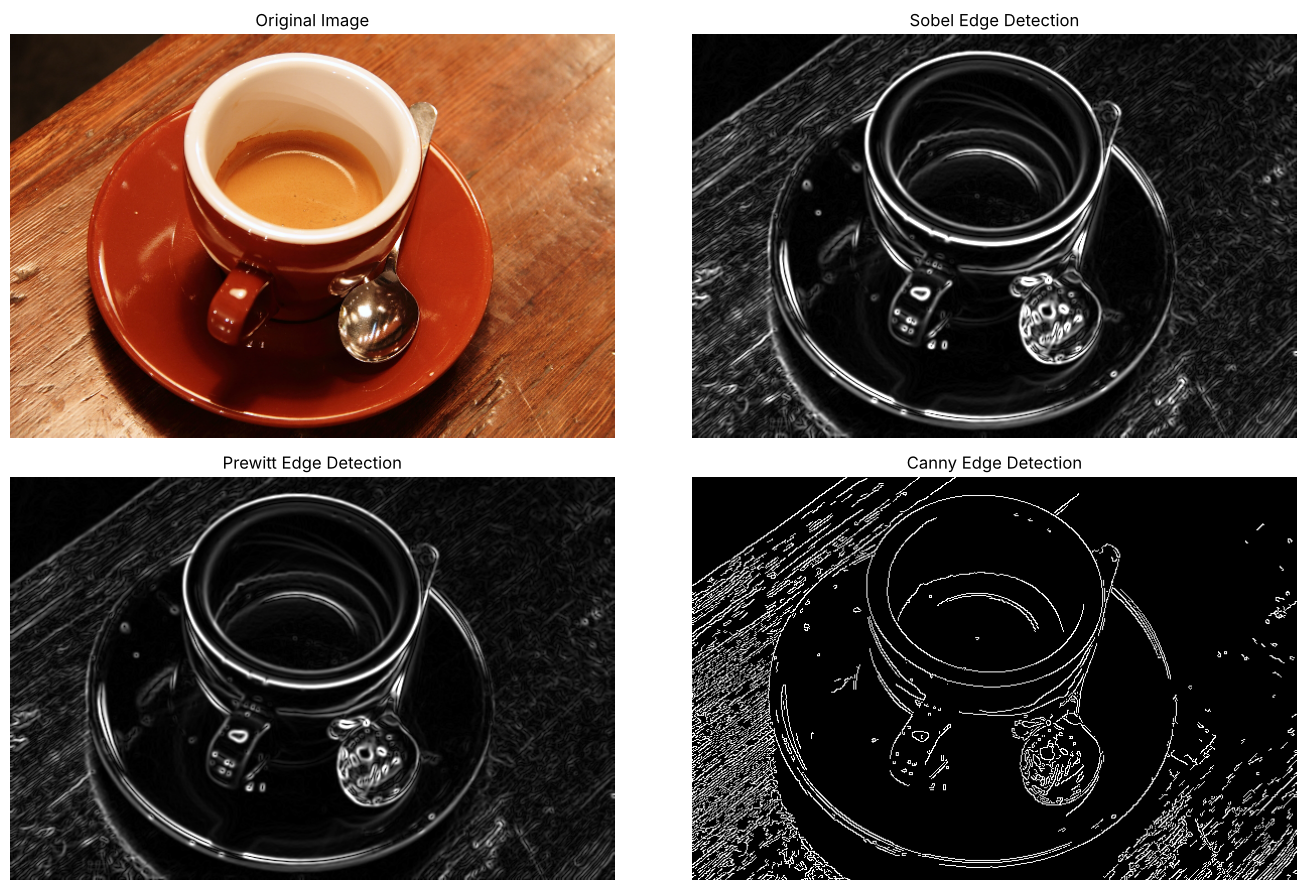

In [5]:
plt.figure(figsize=(14, 9))

plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Edge Detection'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detection'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detection'), plt.axis('off')

plt.tight_layout()
plt.show()

**Comparison:**

- **Sobel** and **Prewitt** give almost the same result because both are gradient based with 3x3 kernels. Sobel edges look a little brighter and stronger since its kernel gives more weight to the center row/column.
- Both of them give thick edges. The strongest edges are the rim of the cup and the outline of the saucer because the contrast there is high (white cup vs dark red saucer). The wood lines on the table also appear as weaker gray edges.
- **Canny** gives thin and clean edges (one pixel wide) and the output is binary, so each pixel is either edge or not. The cup, saucer, handle and spoon outlines are very clear, but it also detected a lot of the wood grain on the table since these lines have a strong enough gradient.

## **Task 2: Investigate the Effect of Canny Thresholds**

Low = 30, High = 90  -->  edge pixels: 41720
Low = 50, High = 150  -->  edge pixels: 31287
Low = 100, High = 200  -->  edge pixels: 20360


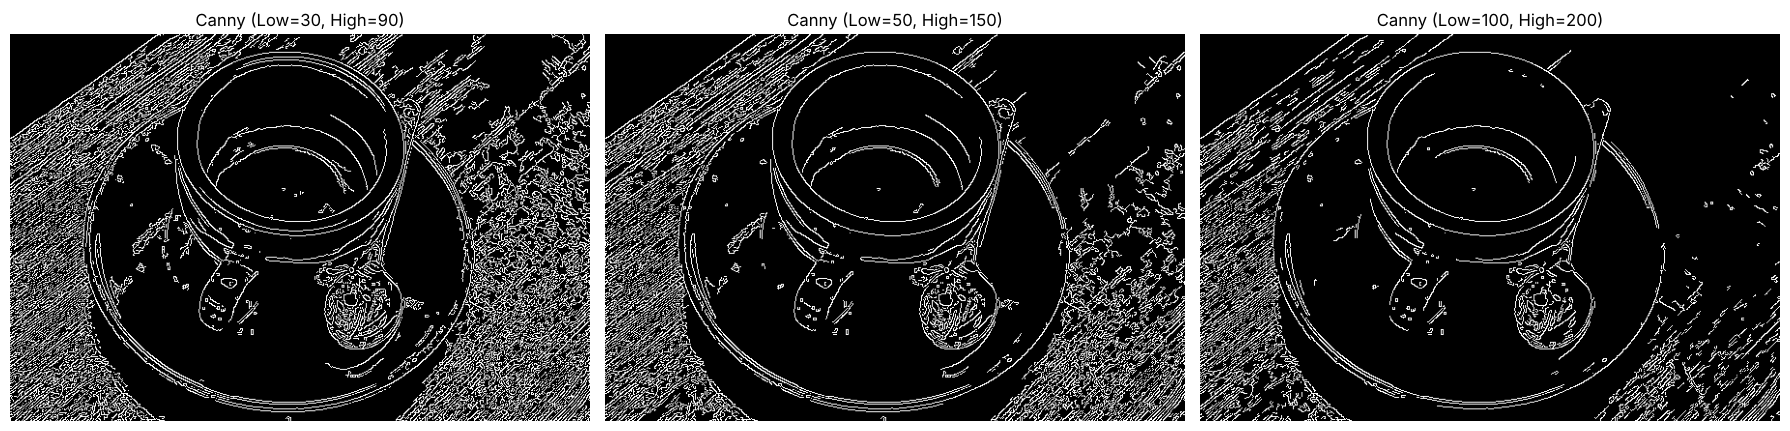

In [6]:
thresholds = [(30, 90), (50, 150), (100, 200)]

plt.figure(figsize=(18, 5))

for i, (low, high) in enumerate(thresholds):
    edges = cv2.Canny(gray, low, high)
    n_edges = np.count_nonzero(edges)
    print(f'Low = {low}, High = {high}  -->  edge pixels: {n_edges}')

    plt.subplot(1, 3, i + 1)
    plt.imshow(edges, cmap='gray')
    plt.title(f'Canny (Low={low}, High={high})')
    plt.axis('off')

plt.tight_layout()
plt.show()

### Explanation

In Canny, any pixel with gradient higher than the **high threshold** is a strong edge, pixels lower than the **low threshold** are removed, and pixels between the two are kept only if they are connected to a strong edge.

- **Low = 30, High = 90:** this gave the largest number of edge pixels (about 41,700). Almost every detail appears, the wood texture covers most of the table and there are many small edges on the saucer and inside the spoon reflection. The image looks crowded and the main objects are harder to see.
- **Low = 50, High = 150:** the number of edges decreased to about 31,300 pixels. The outlines of the cup, saucer, handle and spoon are still complete, and part of the wood texture (specially on the right side) was removed.
- **Low = 100, High = 200:** this gave the lowest number of edges (about 20,400 pixels). Most of the small noisy edges disappeared and mainly the strong edges stay, like the cup rim and the saucer border. Some weak details like the coffee surface edge and parts of the wood are lost or become broken lines.

So increasing the thresholds reduces the number of detected edges and removes noise, but it also hides fine details of the image. Decreasing the thresholds shows more details but also detects more unwanted edges (like the wood texture in this image).